# Нобелевские лауреаты: финальный проект

## Анализ данных о Нобелевских лауреатах

### **Контекст проекта**
В этом задании мы будем работать с датасетом о лауреатах Нобелевской премии. Ваша задача — распарсить и проанализировать эти данные, ответив на ключевые вопросы о закономерностях вручения премий, демографических характеристиках лауреатов и исторических тенденциях.

### **Этап 1: Подготовка данных**

**Задача:** На этом этапе вам надо собрать структурированный список словарей с информацией о лауреатах и призах. Приведем начало нужного нам датасета.

``` {code:python}
[{'id': '745',
  'name': 'A. Michael Spence',
  'gender': 'male',
  'birth_year': 1943,
  'country_birth': 'USA',
  'country_now': 'USA',
  'prizes_relevant': [{'prize_amount': 10000000,
    'prize_amount_adjusted': 15547541,
    'award_year': 2001,
    'category_en': 'Economic Sciences',
    'prize_status': 'received'}],
  'type_': 'person'},
 {'id': '102',
  'name': 'Aage N. Bohr',
  'gender': 'male',
  'birth_year': 1922,
  'country_birth': 'Denmark',
  'country_now': 'Denmark',
  'prizes_relevant': [{'prize_amount': 630000,
    'prize_amount_adjusted': 4304697,
    'award_year': 1975,
    'category_en': 'Physics',
    'prize_status': 'received'}],
  'type_': 'person'}]
  ```

Поскольку информация о лауреатах-людях и лауреатах-организациях структурирована по-разному, а также из-за того, что часть полей в json могут отсутстввовать, необходимо реализовать функции для процессинга словарей, которые будут достаточно обобщаемыми для обоих типов данных.

**Что нужно сделать:**

На входе информация о конкретном лауреате представляет из себя кучу вложенных друг в друга словарей. Из этой структуры нам надо получить плоский словарь вида {atribute: value}, где atribute --- это один из небольшого множества интересных нам атрибутов. При этом в исходном файле
1. пути к атрибутам могут иметь разную длину
2. атрибуты могут отсутствовать
3. атрибуты могут нуждаться в дополнительной обработке (например, поле id в исходных словарях записано как строка.)

Поскольку наивная реализация такого обработчика оказывается довольно громоздкой, вам нужно создать файл json_dict_processing.py, в котором реализован высокоуровневый функционал для решения задачи "обработать вложенный json-словарь"

Главное требование к интерфейсу:
по (вложенному) словарю о лауреате и конфигу (см ниже) надо получить плоский словарь вида {atribute: value}.

Достичь этого можно, например, таким набором функций

* `extract_nested_value(obj, keys)` - извлекает значение из вложенных структур данных по цепочке ключей

* `process_dictionary_with_config(dictionary, config)` - обрабатывает один словарь согласно словару-конфигу (формат конфига см ниже.)

* `process_list_of_dicts_with_config(list_of_dicts, config)` - обрабатывает список словарей, эта функция нужна чтобы обработать список призов.

* `create_processor(config, list_processor=False)` - создает готовый процессор с предзагруженной конфигурацией. В случае, если list_processor == True, внутрь процессора подается process_list_of_dicts_with_config, иначе process_dictionary_with_config.

**Замечание насчет последней функции.**

Планируемое применение этой функции примерно такое:
`laureate_processor = create_processor(PERSON_CONFIG, list_processor=False)`

То есть, create_processor возвращает функцию, которая реализует функционал process_dictionary_with_config но с уже заполненным конфигом. Это повышает читаемость кода и снижает риск перепутать конфиги из-за дублирования кода.


Помимо этого нужно создать файлы-конфиги для данных по призам, лауреатам-людям, и лауреатам-организациям.

КОНФИГ для функций process_dictionary_with_config и process_list_of_dicts_with_config имеет следующий вид
```python
  {'атрибут_который_берем_сырым': ['путь', 'к', 'данным'],  # или
  'атрибут_который_нужно_обработать': (['путь', 'к', 'данным'], функция_обработки)}
  ```
В случае, если атрибут можно взять в итоговый датасет сырым, в values() словаря-конфига будет список path_list.
Если же атрибут еще надо обработать, для него в поле config[attribute] будет tuple вида (path_list, function).

Примеры атрибутов, которые можно взять сырыми: имя, размер приза. Примеры атрибутов, которые нужно обработать: год вручения приза (в сырых данных есть только полная дата, записанная как строка)

После того, как будет создан core.py, создайте конфиги laureates_configs.py и prizes_configs.py

Постарайтесь провалидировать код с помощью assert-ов, вызываемых в ноутбуке или в .py-файлах.

пример использования:

assert 1 == True

**Валидация**

В вашем случае assert должен взять простой словарик с одним вложенным полем и какой-нибудь конфиг-файл.
Также убедитесь, что при обработке данных собственно по лауреатам в них нет странностей (смотрите ниже)

**Атрибуты для ПРИЗА (CONFIG_PRIZE, prizes_configs.py)**

- `prize_amount` - сумма приза → `prizeAmount`
- `prize_amount_adjusted` - скорректированная сумма приза → `prizeAmountAdjusted`
- `award_year` - год вручения приза (преобразуется в целое число) → `awardYear`
- `category_en` - категория на английском → `category.en`
- `prize_status` - статус приза → `prizeStatus`

**Атрибуты для ЧЕЛОВЕКА-ЛАУРЕАТА (CONFIG_PERSON, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - имя лауреата → `knownName.en`
- `gender` - пол → `gender`
- `birth_year` - год рождения (извлекается из даты) → `birth.date`
- `country_birth` - страна рождения → `birth.place.country.en`
- `country_now` - текущая страна → `birth.place.countryNow.en`
- `prizes_relevant` - список призов лауреата → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Атрибуты для ОРГАНИЗАЦИИ-ЛАУРЕАТА (CONFIG_ORG, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - название организации → `orgName.en`
- `founded_year` - год основания (извлекается из даты) → `founded.date`
- `country_founded` - страна основания → `founded.place.country.en`
- `country_now` - текущая страна → `founded.place.countryNow.en`
- `prizes_relevant` - список призов организации → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Вспомогательные функции:**

- `process_year(year_string)` - извлекает год из строки даты (формат "YYYY-MM-DD"). Функция находится в файле laureates_configs.py
- `prize_processor()` - создает процессор для обработки списков призов. Функция находится в файле prizes_configs.py
- `person_processor()` - создает процессор для данных о людях-лауреатах. Функция находится в файле laureates_configs.py
- `org_processor()` - создает процессор для данных об организациях-лауреатах. Функция находится в файле laureates_configs.py

## **Загрузка данных**

API Нобелевского комитета иногда отвечает ошибкой 403, поэтому ответ
сохранён в файл `laureates.json` рядом с ноутбуком. Читаем его сразу в
переменную `laureates`.

In [1]:
import json

FILE_LAUREATES = 'laureates.json'  # ответ API лежит рядом с ноутбуком

with open(FILE_LAUREATES, encoding='utf-8') as file:
    laureates = json.load(file)

## **Обработка лауреатов**

Функция `get_laureate_data` смотрит на ключи словаря: если есть `knownName`,
это *человек*, если `orgName` - *организация*. Для каждого типа берётся свой
конфиг, к результату добавляется поле `type_`. Ниже - проверки (`assert`) на
первом лауреате из условия.

In [2]:
from laureates_configs import process_orgs, process_persons


def get_laureate_data(laureate):
    """определяет тип лауреата и обрабатывает его словарь по нужному конфигу
    knownName в словаре - человек, orgName - организация
    к результату добавляется поле type_ ('person' или 'org')"""
    if 'knownName' in laureate:
        return {**process_persons(laureate), 'type_': 'person'}
    if 'orgName' in laureate:
        return {**process_orgs(laureate), 'type_': 'org'}
    raise ValueError('Неизвестный тип лауреата: ' + str(laureate['id']))


laureates_data = [get_laureate_data(laureate)
                  for laureate in laureates['laureates']]

# проверки на примерах из условия
first = laureates_data[0]
assert first['id'] == 745 and first['name'] == 'A. Michael Spence'
assert first['type_'] == 'person' and first['birth_year'] == 1943
assert first['prizes_relevant'][0]['award_year'] == 2001
assert {item['type_'] for item in laureates_data} == {'person', 'org'}



### **Этап 2: EDA лауреатов**

EDA или Exploratory Data Analysis - первый шаг при работе с любыми данными.

Чтобы начать работать с этой секцией, проведите проведите чисто технический анализ собранных данных.

1. Сколько всего записей?
2. Все ли значения полей заполнены?
3. Если нет, сколько пропусков в каждом из полей? Выведите ответ на этот вопрос в формате `{'field_name': missing_values}`. А какая доля пропусков?
5. Каковы максимальные и минимальные значения поля id и каким годам награждения они соответствуют? Есть ли записи с повторяющимися id? Есть ли пары айди, которые в отсортированном массиве айдишников различаются более, чем на один?

При реализации ответов на эти вопросы, пользуйтесь теми же принципами, что описаны выше. Можете начать с плохого хакерского кода, однако в таком случае в маркдауне пропишите, как будете его обобщать и разносить по функциям и модулям. (об этом ниже)

В основном EDA пользуйтесь аккуратным кодом, разбитым на функции и файлы.

In [3]:
from aggregations import (count, count_missing, get_values, maximum,
                          minimum)
from dataset_helpers import filter_records

persons = filter_records(laureates_data, lambda row: row['type_'] == 'person')
orgs = filter_records(laureates_data, lambda row: row['type_'] == 'org')

# 1 сколько всего записей
print('Всего записей:', count(laureates_data),
      f'(людей: {count(persons)}, организаций: {count(orgs)})')

# 2-3 пропуски: у людей и организаций набор полей разный, поэтому
# считаем отдельно, иначе поле gender «пропущено» у всех организаций
for title, group in (('люди', persons), ('организации', orgs)):
    missing = count_missing(group)
    shares = {field: round(number / count(group), 3)
              for field, number in missing.items()}
    print(f'\nПропуски, {title}:', missing)
    print('Доля пропусков:', shares)

Всего записей: 1028 (людей: 1000, организаций: 28)

Пропуски, люди: {'birth_year': 0, 'country_birth': 3, 'country_now': 3, 'gender': 0, 'id': 0, 'name': 0, 'prizes_relevant': 0, 'type_': 0}
Доля пропусков: {'birth_year': 0.0, 'country_birth': 0.003, 'country_now': 0.003, 'gender': 0.0, 'id': 0.0, 'name': 0.0, 'prizes_relevant': 0.0, 'type_': 0.0}

Пропуски, организации: {'country_founded': 4, 'country_now': 4, 'founded_year': 1, 'id': 0, 'name': 0, 'prizes_relevant': 0, 'type_': 0}
Доля пропусков: {'country_founded': 0.143, 'country_now': 0.143, 'founded_year': 0.036, 'id': 0.0, 'name': 0.0, 'prizes_relevant': 0.0, 'type_': 0.0}


Теперь разберём поле **id**: найдём минимальное и максимальное значения (и
годы наград этих лауреатов), проверим дубликаты и **разрывы** в нумерации.

In [4]:
# 5 поле id: максимум, минимум, дубликаты, пропуски в нумерации


def get_award_years(laureate):
    return [prize['award_year'] for prize in laureate['prizes_relevant']]


ids = get_values(laureates_data, 'id')
for label, function in (('Минимальный', minimum), ('Максимальный', maximum)):
    extreme_id = function(laureates_data, 'id')
    extreme = filter_records(laureates_data,
                             lambda row: row['id'] == extreme_id)[0]
    print(label, 'id:', extreme_id, extreme['name'],
          '| годы наград:', get_award_years(extreme))

print('Повторяющиеся id:', len(ids) - len(set(ids)))

sorted_ids = sorted(ids)
gaps = [(a, b) for a, b in zip(sorted_ids, sorted_ids[1:]) if b - a > 1]
print('Пар соседних id с разницей больше 1:', len(gaps))
print('Первые пять:', gaps[:5])

Минимальный id: 1 Wilhelm Conrad Röntgen | годы наград: [1901]
Максимальный id: 1070 Michael Woodford | годы наград: [2026]
Повторяющиеся id: 0
Пар соседних id с разницей больше 1: 24
Первые пять: [(6, 8), (93, 95), (169, 172), (255, 257), (468, 470)]


**Выводы EDA.** В данных 1028 записей: 1000 людей и 28 организаций. У
организаций нет пола, но это не «дыра» в данных, а особенность типа, поэтому
пропуски считались отдельно для людей и организаций. Дубликатов id нет.
В нумерации id есть 24 разрыва (например, нет id 7): это, вероятно, записи,
которых нет в выгрузке. Самый большой id (1070) относится к награде 2026 года,
самый маленький (1) - к первой премии 1901 года.


Поскольку это курс по Python, а не по статистике или визуализации данных, мы не задаем жесткие рамки того, что вы должны проанализировать.
Однако это отличная возможность представить себя в роли разработчика базы данных или, например, библиотеки pandas.

В коде нужно соблюдать следующие правила:

1. должны быть реализованы  несколько способов работы с данными (среднее/медианное/максимальное значение метрики, количество примеров, вывод топ-N объектов по значению метрики).
2. анализ выбранных вами тем должен включать в себя анализ метрик в тотале, по категориям и в динамике по годам или десятилетиям.
3. проанализировать стоит 2-3 темы. Вы можете использовать темы ниже или взять свои.
2. вывод ноутбука должен быть понятен обывателю. Это может быть визуализация в matplotlib/seaborn. Сопровождайте вывод markdown-ячейками с вашими  мыслями, пояснениями и инсайтами, которые удалось извлечь.
3. Нельзя использовать pandas и numpy, но можно вдохновляться их интерфейсом и функционалом при дизайне ваших функций.


Из пункта 2 следует, что вам придется работать не только с атрибутами лауреатов, но и самих призов.
Информацию о призах нужно доставать и записывать как атрибут уже лауреата. Функции, работающие с призами (например, факт того, что лауреат отказался от какого-то из призов) можно реализовать в ноутбуке, но если вы создаете более общие вспомогательные функции, выносите их в отдельные модули.

Мы рекомендуем следующую структуру кода:

* `dataset_helpers.py` в котором реализованы фильтрация списка словарей (плоских) по условиям (аналог sql-ного where), а также аналог sql-ного групбая. А также функция для применения агрегаций к списку словарей
* `aggregations.py` в котором реализованы функции расчета среднего/медианы/других эвристик и мб вывод топ n-значений по какой-то метрике.
* `atribute_manager.py` в котором реализован переиспользуемый интерфейс для добавления (и мб удаления) полей.

Замечание насчет group-by.

На игрушесном примере она может работать примерно так:
```
    Входные данные: [
        {'name': 'Alice', 'country': 'USA', 'age': 25},
        {'name': 'Bob', 'country': 'UK', 'age': 30},
        {'name': 'Charlie', 'country': 'USA', 'age': 25}
    ]
    
    group_by_attributes(data, ['country', 'age']) → {
        ('USA', 25): [
            {'name': 'Alice', 'country': 'USA', 'age': 25},
            {'name': 'Charlie', 'country': 'USA', 'age': 25}
        ],
        ('UK', 30): [
            {'name': 'Bob', 'country': 'UK', 'age': 30}
        ]
    }
```

Замечание насчет agregations.py
1. Агрегации соответственно должны применяться к спискам вида [
    {'name': 'Alice', 'country': 'USA', 'age': 25},
    {'name': 'Charlie', 'country': 'USA', 'age': 25}
]
2. Пользуйтесь модулем statistics из стандартной библиотеки питона.


Эта структура одна из возможных для организации вашего кода, главное, чтобы эти достаточно общие функции блыи переиспользованы

----------

При анализе данных вам понадобятся более конкретные функции, например filter_by_num_prizes или output_metric_by_category. Их пишите прямо в ноутбуке и сопровождайте коментами.

Ниже мы приводим некоторые примеры вопросов, которые может быть интересно задать к данным, но если у вас есть желание, можете поисследовать датасет с любой интересной вам стороны!


**2.1. Топ-статистика по странам**
- Определите топ-5 стран по общему количеству лауреатов
- Постройте аналогичные рейтинги отдельно по категориям (физика, химия, медицина и т.д.)

**2.2. Возраст при награждении**
- Рассчитать средний возраст лауреатов на момент получения **первого** приза. Рассмотрите только лауреатов-людей.
- Исследуйте, как средний возраст получения первого приза различается по категориям
- Различаются ли средний и медианный возрасты?

**2.3. Гендерное распределение**
- Как менялось количество женщин-лауреатов по десятилетиям?
- Сравните распределение лауреаток по категориям. Выведите значения суммарно за все годы и по декадам.
- В какой из категорий больше всего женщин лауреаток изначально и в последние пару десятилетий?

**2.4. Миграции лауреатов**
- У скольки лауреатов исходная страна и страна на момент вручения нобелевской премии различаются? Всегда ли это различие объясняется миграцией? Добавьте вспомогательное поле 'country_of_origin_adjusted_for_migration', чтобы различие между этим полем и страной на момент вручения объяснялось миграцией.
- Выявите страны с наибольшей долей "оттекших" и "притекших" лауреатов.
- Есть ли оттоки среди организаций?

**2.5. Многократные лауреаты**
- Найдите лауреатов, получившие больше одного приза. Кто получил больше 2 раз?
- Совпадает ли категория второго приза с первой?  
- Сколько в среднем времени прошло между получением первой и второй премии?

**2.6 Отказы от премий**
- Определите, в каких категориях чаще отказывались от премий?
- Есть ли отказы среди организаций?

### **Подготовка к анализу**

Анализируем **3 темы**: топ стран (2.1), возраст при награждении (2.2) и
гендерное распределение (2.3). Для каждой смотрим метрики в тотале, по
категориям и по десятилетиям.

Единица анализа для тем 2.1 и 2.3 - **пара «лауреат + приз»**: человек,
получивший награды в двух категориях, учитывается дважды (таких всего 8
лишних призов на 1028 лауреатов). В анализ берём только полученные призы
(`received`): 2 отказа и 1 ограниченный приз исключены. Плоские записи о
призах строятся из лауреатов, а дополнительные поля добавляются через `atribute_manager`.

In [5]:
import matplotlib.pyplot as plt

from aggregations import mean, median, top_n
from atribute_manager import add_attribute
from dataset_helpers import apply_aggregation, group_by_attributes


def make_prize_records(laureates_list):
    """одна запись на каждый приз: данные лауреата + данные приза"""
    records = []
    for laureate in laureates_list:
        for prize in laureate['prizes_relevant']:
            records.append({**laureate, **prize})
    return records


def get_decade(record):
    return record['award_year'] // 10 * 10


def get_age(record):
    return record['award_year'] - record['birth_year']


prizes = make_prize_records(laureates_data)
prizes = add_attribute(prizes, 'decade', get_decade)
prizes = [row for row in prizes if row['prize_status'] == 'received']

# возраст при первом призе: только люди с известным годом рождения
first_prizes = []
for person in persons:
    if person['birth_year'] is None:
        continue
    first_prize = min(person['prizes_relevant'],
                      key=lambda prize: prize['award_year'])
    first_prizes.append({**person, **first_prize})
first_prizes = add_attribute(first_prizes, 'age', get_age)
first_prizes = add_attribute(first_prizes, 'decade', get_decade)

print('Призов в анализе:', len(prizes), '| людей с первым призом:',
      len(first_prizes))


def metric_by(records, attributes, aggregation, *args):
    """метрика по группам: group by + агрегация"""
    return apply_aggregation(group_by_attributes(records, attributes),
                             aggregation, *args)


def top_by_category(records, category_field='category_en', n=5):
    """топ-n групп по размеру внутри каждой категории"""
    result = {}
    for (category,), group in group_by_attributes(
            records, [category_field]).items():
        sizes = metric_by(group, ['country_now'], len)
        result[category] = [(key[0], value) for key, value in top_n(sizes, n)]
    return result

Призов в анализе: 1033 | людей с первым призом: 1000


### **2.1. Топ-статистика по странам**
Страна - это современное название страны (`country_now`), чтобы, например,
рождённые в Российской империи и СССР не разъехались по разным строкам.

Топ-5 стран по числу призов: [('USA', 309), ('United Kingdom', 97), ('Germany', 86), ('France', 65), ('Japan', 32)]
Economic Sciences: [('USA', 56), ('United Kingdom', 7), ('Canada', 5), ('France', 5), ('the Netherlands', 4)]
Physics: [('USA', 72), ('Germany', 27), ('United Kingdom', 25), ('France', 13), ('Japan', 12)]
Chemistry: [('USA', 60), ('United Kingdom', 27), ('Germany', 26), ('France', 12), ('Japan', 9)]
Literature: [('France', 11), ('USA', 10), ('Sweden', 7), ('Poland', 7), ('Germany', 7)]
Peace: [('USA', 26), ('France', 12), ('Switzerland', 11), ('United Kingdom', 7), ('Russia', 5)]
Physiology or Medicine: [('USA', 85), ('United Kingdom', 25), ('Germany', 20), ('France', 12), ('Sweden', 8)]
1900-е: France (9 из 57)
1910-е: Germany (6 из 40)
1920-е: Germany (10 из 54)
1930-е: USA (14 из 56)
1940-е: USA (14 из 43)
1950-е: USA (21 из 71)
1960-е: USA (22 из 78)
1970-е: USA (33 из 103)
1980-е: USA (33 из 97)
1990-е: USA (43 из 104)
2000-е: USA (54 из 123)
2010-е: USA (39 из 121)


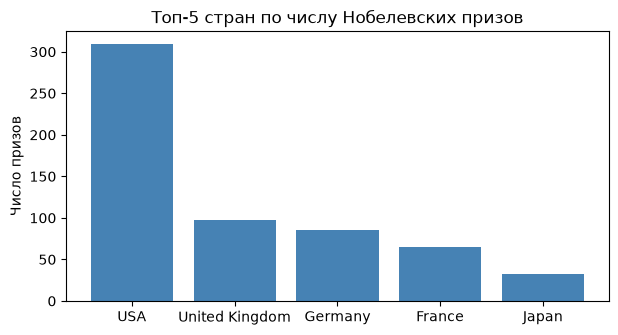

In [6]:
by_country = metric_by(prizes, ['country_now'], len)
top_countries = [(key[0], value) for key, value in top_n(by_country, 5)]
print('Топ-5 стран по числу призов:', top_countries)

for category, top in top_by_category(prizes).items():
    print(f'{category}: {top}')

# динамика: лидер каждого десятилетия
decades = group_by_attributes(prizes, ['decade'])
for (decade,), group in sorted(decades.items()):
    sizes = metric_by(group, ['country_now'], len)
    (leader,), number = top_n(sizes, 1)[0]
    print(f'{decade}-е: {leader} ({number} из {len(group)})')

names, values = zip(*top_countries)
plt.figure(figsize=(7, 3.5))
plt.bar(names, values, color='steelblue')
plt.title('Топ-5 стран по числу Нобелевских призов')
plt.ylabel('Число призов')
plt.show()

**Вывод.** США с огромным отрывом лидируют и в целом, и почти во всех
категориях; за ними идут Великобритания и Германия. Лидер по десятилетиям
показывает, как сместился центр науки: в 1900-е лидирует Франция, в
1910-20-е - Германия, а с 1930-х - США. Исключение по категориям - литература:
там впереди Франция, а США лишь второй.

### **2.2. Возраст при награждении**
Только люди с известным годом рождения, возраст считается на момент
**первого** приза.

Людей в выборке: 1000
Средний возраст: 60.6 | медианный: 61.0

По категориям (среднее / медиана / число):
Chemistry                 / 59.4 / 58 / 199
Economic Sciences         / 67.2 / 67 / 101
Literature                / 65.0 / 67 / 123
Peace                     / 61.0 / 62.0 / 112
Physics                   / 57.8 / 56.0 / 230
Physiology or Medicine    / 59.0 / 58 / 235

Средний возраст по десятилетиям: {1900: 57.8, 1910: 53.1, 1920: 55.0, 1930: 51.6, 1940: 58.0, 1950: 54.3, 1960: 56.4, 1970: 59.3, 1980: 60.5, 1990: 62.1, 2000: 65.9, 2010: 66.9, 2020: 69.4}


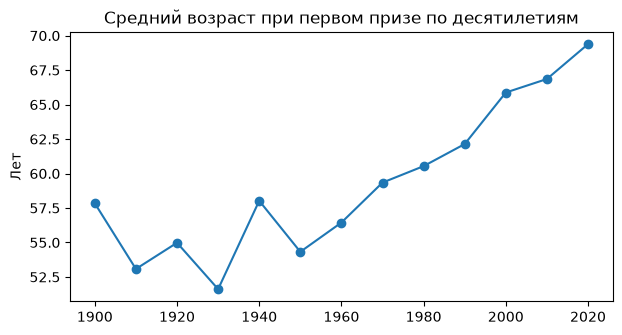

In [7]:
print('Людей в выборке:', len(first_prizes))
print('Средний возраст:', round(mean(first_prizes, 'age'), 1),
      '| медианный:', median(first_prizes, 'age'))

print('\nПо категориям (среднее / медиана / число):')
for (category,), group in sorted(group_by_attributes(
        first_prizes, ['category_en']).items()):
    print(f'{category:25}', round(mean(group, 'age'), 1),
          median(group, 'age'), len(group), sep=' / ')

mean_by_decade = {key[0]: value for key, value in sorted(
    metric_by(first_prizes, ['decade'], mean, 'age').items())}
print('\nСредний возраст по десятилетиям:',
      {decade: round(age, 1) for decade, age in mean_by_decade.items()})

plt.figure(figsize=(7, 3.5))
plt.plot(list(mean_by_decade), list(mean_by_decade.values()), marker='o')
plt.title('Средний возраст при первом призе по десятилетиям')
plt.ylabel('Лет')
plt.show()

**Вывод.** Средний (60.6) и медианный (61) возраст почти совпадают, то есть
выбросов, которые сильно сдвигали бы среднее, мало. Самые «молодые» премии - по
физике (57.8), самые «взрослые» - по экономике (67.2) и литературе (65.0).
Со временем возраст растёт: с 52-55 лет в 1930-50-х до 69 лет в 2020-х.

### **2.3. Гендерное распределение**
Считаем призы, полученные женщинами (среди людей).

Призов у женщин: 70 из 1002
По десятилетиям: {1900: 3, 1910: 1, 1920: 2, 1930: 3, 1940: 3, 1960: 3, 1970: 4, 1980: 4, 1990: 7, 2000: 11, 2010: 13, 2020: 16}
По категориям за всё время: [('Peace', 21), ('Literature', 19), ('Physiology or Medicine', 14), ('Chemistry', 8), ('Physics', 5), ('Economic Sciences', 3)]

Женщины: категории по десятилетиям (с 1960-х)
Chemistry                 {1960: 1, 2000: 1, 2010: 1, 2020: 3}
Economic Sciences         {2000: 1, 2010: 1, 2020: 1}
Literature                {1960: 1, 1990: 3, 2000: 3, 2010: 3, 2020: 4}
Peace                     {1970: 3, 1980: 1, 1990: 3, 2000: 2, 2010: 5, 2020: 4}
Physics                   {1960: 1, 2010: 1, 2020: 2}
Physiology or Medicine    {1970: 1, 1980: 3, 1990: 1, 2000: 4, 2010: 2, 2020: 2}
Лидер до 1980: Peace (6)
Лидер с 2000: Peace (11)


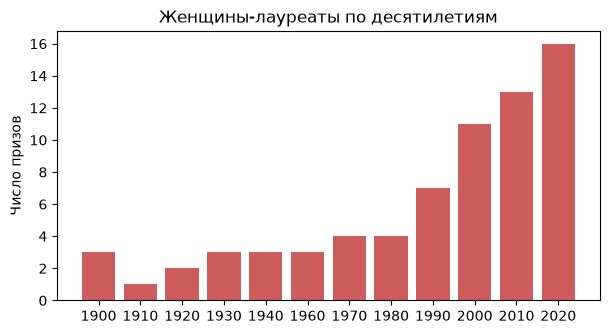

In [8]:
women = filter_records(prizes, lambda row: row.get('gender') == 'female')
print('Призов у женщин:', len(women), 'из',
      len(filter_records(prizes, lambda row: row['type_'] == 'person')))

by_decade = {key[0]: value for key, value in sorted(
    metric_by(women, ['decade'], len).items())}
print('По десятилетиям:', by_decade)

by_category = metric_by(women, ['category_en'], len)
print('По категориям за всё время:',
      [(key[0], value) for key, value in top_n(by_category, 10)])

print('\nЖенщины: категории по десятилетиям (с 1960-х)')
for (category,), group in sorted(
        group_by_attributes(women, ['category_en']).items()):
    by_decade_in_category = metric_by(group, ['decade'], len)
    print(f'{category:25}', {key[0]: value for key, value in sorted(
        by_decade_in_category.items()) if key[0] >= 1960})

for label, period in (('до 1980', lambda row: row['award_year'] < 1980),
                      ('с 2000', lambda row: row['award_year'] >= 2000)):
    sizes = metric_by(filter_records(women, period), ['category_en'], len)
    (leader,), number = top_n(sizes, 1)[0]
    print(f'Лидер {label}: {leader} ({number})')

plt.figure(figsize=(7, 3.5))
plt.bar([str(decade) for decade in by_decade], list(by_decade.values()),
        color='indianred')
plt.title('Женщины-лауреаты по десятилетиям')
plt.ylabel('Число призов')
plt.show()

**Вывод.** Женщины получили 70 из 1002 призов людям. До 1990-х их было 1-4 за
десятилетие, а в 2000-х, 2010-х и 2020-х - 11, 13 и 16. Лидер и за всё время, и
до 1980, и с 2000 года - премия мира (21 приз), затем литература (19) и
медицина (14). Физика (5) и экономика (3) остаются самыми «мужскими».

## **Итоговые выводы**

Что получилось: сырой JSON из 1028 записей превращён в плоский датасет
(1000 людей и 28 организаций), на котором посчитаны метрики по трём темам.

- **Страны.** США с большим отрывом лидируют по числу призов (309), за ними
  Великобритания (97), Германия (86), Франция (65) и Япония (32).
  Исключение - литература, где впереди Франция.
- **Возраст.** Средний возраст при первом призе 60.6 года, медиана 61.
  Моложе всех получают премию по физике, старше всех - по экономике.
  Со временем возраст растёт: с 52-55 лет в 1930-50-х до 69 лет в 2020-х.
- **Женщины.** Из 1002 призов людям женщинам достались 70. Их доля заметно
  выросла с 1990-х, а по числу лауреаток лидирует премия мира.
- **Данные.** Дубликатов id нет, пропусков мало: у людей только страна рождения
  (3 записи), у организаций - страна основания (4 записи из 28).

Бонусное задание (тексты мотиваций) не выполнялось.

---------

## Бонусное задание на +2 балла


### Лингвистический анализ мотиваций**

**5.1. Анализ текстов мотиваций**
- Соберите корпус текстов мотиваций вручения премий. Для этого измените конфиг обработки призов.
- Выделите самые частые топ-50 слов. Какие из этих слов самые частые в принципе в английском языке (такие, как for, the и другие), а какие кажутся важными именно в контексте вручения Нобелевской премии (например, 'chemistry')?
- Самые частые слова, которые также являются частыми во всем английском языке занесите в отдельный конфиг-файл под названием `stopwords.py`. Вычистите их из текстов. Какие слова являются самыми частыми теперь? Сравните множества топ-10 самых частых слов по разным категориям


- Если есть желание, посчитайте TF-IDF + сравнените топ слов по этой метрике с просто самыми популярными словами)